###  **Title: DSC680-T301 Applied Data Science (2271-1)**
####  **Professor:** *Xu Ashton*
####  **Date: 26 Sep 2026**
####  **Author:** *Akhil Anand Thazhaniyil Muralidharan*
####  **Description:** Week4 Milestone 3: Predicting Network Service Degradation Using Telecom Operational Data.

*************

TTelecommunication services depend on stable signal quality, sufficient throughput, and timely response to operational faults. This project evaluates whether historical network performance and event data can support earlier identification of service degradation. Three public source groups were analyzed independently: cellular measurements, Indian mobile speed tests, and Telstra fault-severity records. The analysis found meaningful variation by environment, operator, region, and fault class. A reproducible Random Forest baseline achieved 0.640 holdout accuracy and 0.587 macro F1. Class 2 recall reached 0.759, but precision was 0.385, demonstrating that rare severe faults can be detected at the cost of false-positive alerts. The final recommendation is an explainable, human-reviewed early-warning workflow rather than unattended automated remediation.
************

### Setup and Reproducibility
The random seed is fixed at 42. The notebook keeps the three source groups separate because their identifiers and observation units are incompatible.

In [16]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from joblib import parallel_backend
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
DATA_DIR = next((p for p in [Path.cwd()/'DataSets'] if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Create a DataSets folder beside the notebook and add the nine Milestone 2 CSV files.')
OUTPUT_DIR = Path.cwd()/'milestone3_outputs'; OUTPUT_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns', 100)
#print('Data directory:', DATA_DIR.resolve())

### Load Data

In [3]:
csv_files = sorted(DATA_DIR.rglob('*.csv'))
datasets = {p.relative_to(DATA_DIR).as_posix(): pd.read_csv(p) for p in csv_files}
inventory = pd.DataFrame([{'file':k,'rows':len(v),'columns':v.shape[1],'missing_values':int(v.isna().sum().sum()),'duplicate_rows':int(v.duplicated().sum())} for k,v in datasets.items()])
display(inventory.sort_values('file'))


,file,rows,columns,missing_values,duplicate_rows
0,April_MySpeed_2021.csv,275078,6,709,98266
1,cellular-network-performance-data.csv,463,11,0,0
2,telstra_dataSets/event_type.csv,31170,2,0,0
3,telstra_dataSets/log_feature.csv,58671,3,0,0
4,telstra_dataSets/resource_type.csv,21076,2,0,0
5,telstra_dataSets/sample_submission.csv,11171,4,0,0
6,telstra_dataSets/severity_type.csv,18552,2,0,0
7,telstra_dataSets/test.csv,11171,2,0,0
8,telstra_dataSets/train.csv,7381,3,0,0


### Prepare Cellular, Speed-Test, and Telstra Tables

In [4]:
def extract_number(series):
    return pd.to_numeric(series.astype(str).str.extract(r'(\d+)', expand=False), errors='coerce')
cellular = datasets['cellular-network-performance-data.csv'].copy()
cellular['Timestamp'] = pd.to_datetime(cellular['Timestamp'], errors='coerce')
cellular_numeric=['Signal Strength (dBm)','SNR','Call Duration (s)','Attenuation','Distance to Tower (km)']
for c in cellular_numeric: cellular[c]=pd.to_numeric(cellular[c],errors='coerce')
cellular['potential_degradation']=(cellular['Signal Strength (dBm)'] < -100) | (cellular['SNR'] < 15)
cellular=cellular.dropna(subset=['Timestamp','Signal Strength (dBm)','SNR','Distance to Tower (km)'])
speed_tests=datasets['April_MySpeed_2021.csv'].copy().rename(columns={'download':'direction'})
speed_tests['speed']=pd.to_numeric(speed_tests['speed'],errors='coerce')
speed_tests['signal_strength']=pd.to_numeric(speed_tests['signal_strength'],errors='coerce')
speed_tests['direction']=speed_tests['direction'].astype(str).str.lower().str.strip()
speed_tests['operator']=speed_tests['operator'].astype(str).str.upper().str.strip()
speed_tests['lsa']=speed_tests['lsa'].replace({'NA':np.nan})
train=datasets['telstra_dataSets/train.csv'].copy(); events=datasets['telstra_dataSets/event_type.csv'].copy(); resources=datasets['telstra_dataSets/resource_type.csv'].copy(); severity=datasets['telstra_dataSets/severity_type.csv'].copy(); logs=datasets['telstra_dataSets/log_feature.csv'].copy()
train['location_code']=extract_number(train['location']); events['event_code']=extract_number(events['event_type']); resources['resource_code']=extract_number(resources['resource_type']); severity['severity_code']=extract_number(severity['severity_type']); logs['log_code']=extract_number(logs['log_feature']); logs['volume']=pd.to_numeric(logs['volume'],errors='coerce').fillna(0)
severity_agg=severity.groupby('id').agg(severity_type_count=('severity_code','nunique'),severity_code_max=('severity_code','max'))
event_agg=events.groupby('id').agg(event_type_count=('event_code','nunique'))
resource_agg=resources.groupby('id').agg(resource_type_count=('resource_code','nunique'))
log_agg=logs.groupby('id').agg(log_feature_count=('log_code','nunique'),total_log_volume=('volume','sum'),max_log_volume=('volume','max'),mean_log_volume=('volume','mean'))
fault=train.merge(severity_agg,on='id',how='left').merge(event_agg,on='id',how='left').merge(resource_agg,on='id',how='left').merge(log_agg,on='id',how='left')
feature_cols=['location_code','severity_type_count','severity_code_max','event_type_count','resource_type_count','log_feature_count','total_log_volume','max_log_volume','mean_log_volume']
fault[feature_cols]=fault[feature_cols].fillna(0)
display(pd.DataFrame({'table':['Cellular','Speed tests','Telstra faults'],'rows':[len(cellular),len(speed_tests),len(fault)]}))


,table,rows
0,Cellular,462
1,Speed tests,275078
2,Telstra faults,7381


### Reproduce Core Exploratory Evidence

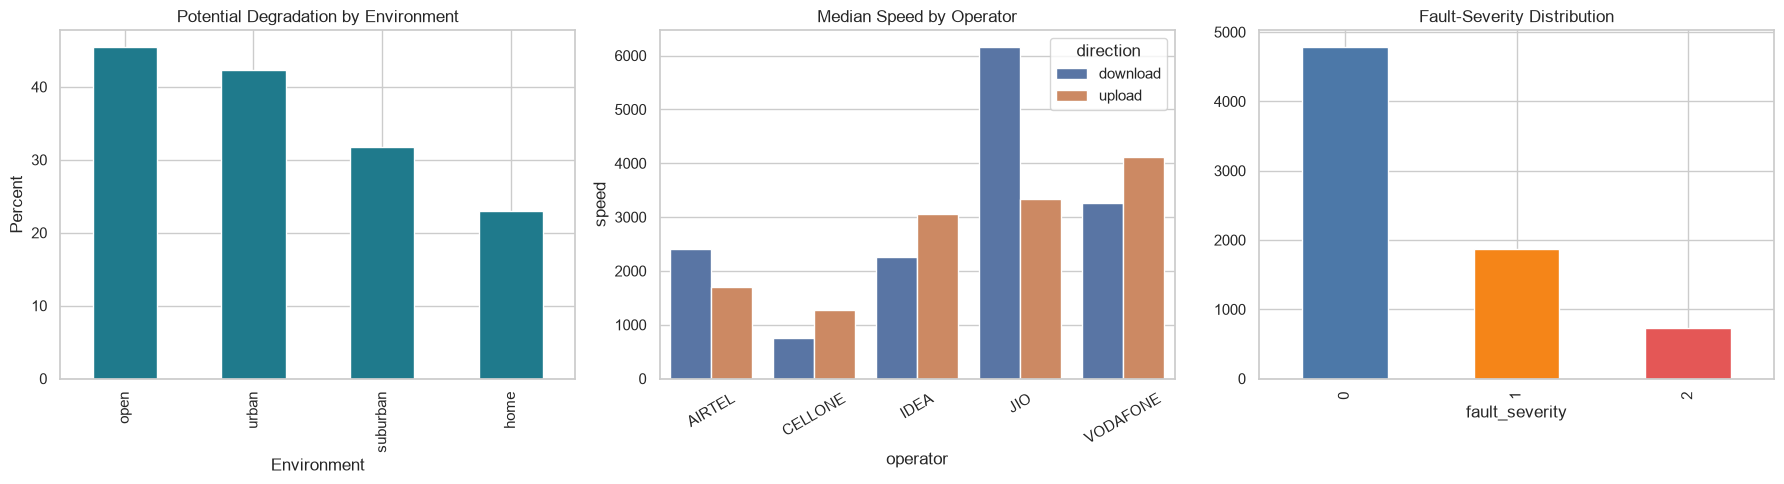

In [5]:
env_rate=cellular.groupby('Environment')['potential_degradation'].mean().mul(100).sort_values(ascending=False)
operator_speed=speed_tests.dropna(subset=['speed']).groupby(['operator','direction'],as_index=False)['speed'].median()
severity_counts=fault['fault_severity'].value_counts().sort_index()
fig,axes=plt.subplots(1,3,figsize=(18,5))
env_rate.plot(kind='bar',ax=axes[0],color='#1F7A8C',title='Potential Degradation by Environment'); axes[0].set_ylabel('Percent')
sns.barplot(data=operator_speed,x='operator',y='speed',hue='direction',ax=axes[1]); axes[1].set_title('Median Speed by Operator'); axes[1].tick_params(axis='x',rotation=30)
severity_counts.plot(kind='bar',ax=axes[2],color=['#4C78A8','#F58518','#E45756'],title='Fault-Severity Distribution')
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'core_exploration.png',dpi=300,bbox_inches='tight'); plt.show()


### Baseline Random Forest
A stratified holdout and balanced class weights reproduce the Milestone 2 baseline.

              precision    recall  f1-score   support

           0      0.868     0.646     0.741       957
           1      0.455     0.581     0.511       375
           2      0.385     0.759     0.510       145

    accuracy                          0.640      1477
   macro avg      0.569     0.662     0.587      1477
weighted avg      0.716     0.640     0.660      1477



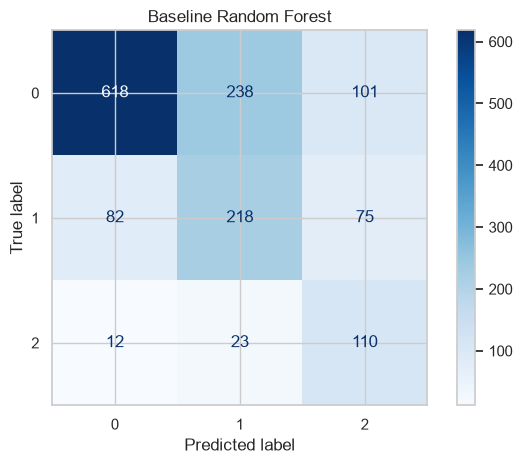

In [6]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, confusion_matrix, f1_score, accuracy_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from sklearn.inspection import permutation_importance
X=fault[feature_cols].astype(float); y=fault['fault_severity']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=RANDOM_STATE,stratify=y)
baseline=RandomForestClassifier(n_estimators=400,random_state=RANDOM_STATE,class_weight='balanced',min_samples_leaf=2,n_jobs=-1)
baseline.fit(X_train,y_train); base_pred=baseline.predict(X_test)
print(classification_report(y_test,base_pred,digits=3))
ConfusionMatrixDisplay.from_predictions(y_test,base_pred,cmap='Blues'); plt.title('Baseline Random Forest'); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'baseline_confusion_matrix.png',dpi=300); plt.show()


### Five-Fold Cross-Validation
Cross-validation reports variability instead of relying on a single holdout split.

In [7]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
scoring={'accuracy':'accuracy','macro_f1':'f1_macro','weighted_f1':'f1_weighted'}
cv_result=cross_validate(baseline,X,y,cv=cv,scoring=scoring,n_jobs=-1)
cv_summary=pd.DataFrame({k.replace('test_',''):v for k,v in cv_result.items() if k.startswith('test_')}).agg(['mean','std']).T
print(cv_summary); cv_summary.to_csv(OUTPUT_DIR/'baseline_cross_validation.csv')


                 mean       std
accuracy     0.653705  0.012235
macro_f1     0.601939  0.009912
weighted_f1  0.670235  0.012151


### Randomized Hyperparameter Search
Macro F1 is optimized because each severity class should contribute equally to the tuning objective.

In [15]:
param_dist={'n_estimators':[300,500,700,900],'max_depth':[None,8,12,18,25],'min_samples_split':[2,5,10,20],'min_samples_leaf':[1,2,4,8],'max_features':['sqrt','log2',0.7],'class_weight':['balanced','balanced_subsample']}
search=RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE,n_jobs=1),param_distributions=param_dist,n_iter=30,scoring='f1_macro',cv=cv,random_state=RANDOM_STATE,n_jobs=-1,verbose=1,return_train_score=True)
with parallel_backend('threading'):
    search.fit(X_train,y_train)
tuned=search.best_estimator_; tuned_pred=tuned.predict(X_test)
print('Best parameters:',search.best_params_); print('Best CV macro F1:',round(search.best_score_,3)); print(classification_report(y_test,tuned_pred,digits=3))
pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(20).to_csv(OUTPUT_DIR/'hyperparameter_search_top20.csv',index=False)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': 'balanced_subsample'}
Best CV macro F1: 0.616
              precision    recall  f1-score   support

           0      0.865     0.647     0.740       957
           1      0.459     0.595     0.518       375
           2      0.385     0.731     0.505       145

    accuracy                          0.642      1477
   macro avg      0.570     0.658     0.588      1477
weighted avg      0.714     0.642     0.661      1477



### Model Comparison
HistGradientBoosting provides a second algorithmic perspective. Sample weights compensate for class imbalance.

,model,accuracy,macro_f1,weighted_f1
2,HistGradientBoosting,0.655,0.608,0.673
1,Tuned Random Forest,0.642,0.588,0.661
0,Baseline Random Forest,0.640,0.587,0.660


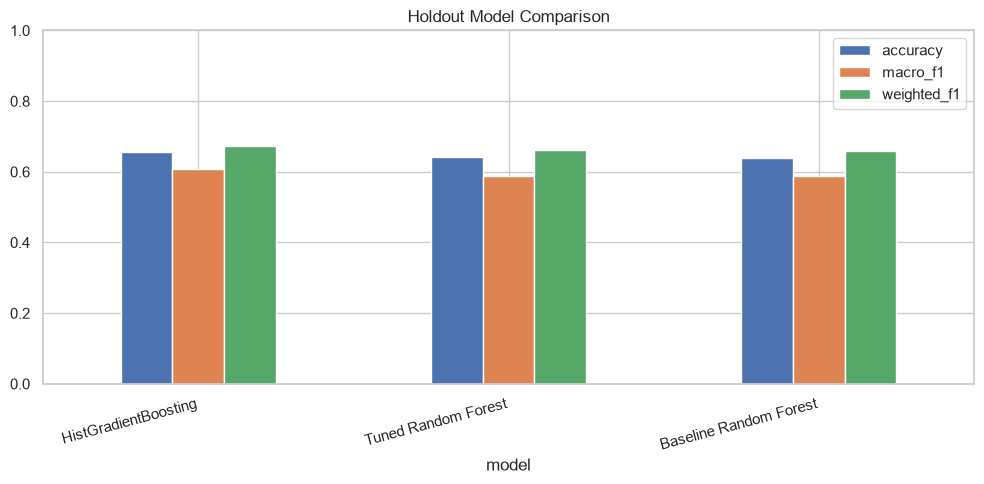

In [9]:
from sklearn.utils.class_weight import compute_sample_weight
hgb=HistGradientBoostingClassifier(max_iter=300,learning_rate=.05,max_leaf_nodes=31,l2_regularization=1.0,random_state=RANDOM_STATE)
hgb.fit(X_train,y_train,sample_weight=compute_sample_weight('balanced',y_train)); hgb_pred=hgb.predict(X_test)
rows=[]
for name,pred in [('Baseline Random Forest',base_pred),('Tuned Random Forest',tuned_pred),('HistGradientBoosting',hgb_pred)]:
    rows.append({'model':name,'accuracy':accuracy_score(y_test,pred),'macro_f1':f1_score(y_test,pred,average='macro'),'weighted_f1':f1_score(y_test,pred,average='weighted')})
comparison=pd.DataFrame(rows).sort_values('macro_f1',ascending=False); display(comparison.round(3)); comparison.to_csv(OUTPUT_DIR/'model_comparison.csv',index=False)
ax=comparison.set_index('model')[['accuracy','macro_f1','weighted_f1']].plot(kind='bar',figsize=(10,5)); ax.set_ylim(0,1); ax.set_title('Holdout Model Comparison'); plt.xticks(rotation=15,ha='right'); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'model_comparison.png',dpi=300); plt.show()


### Multiclass Precision-Recall Curves
Precision-recall analysis is useful for the imbalanced target because it makes false-alert tradeoffs visible.

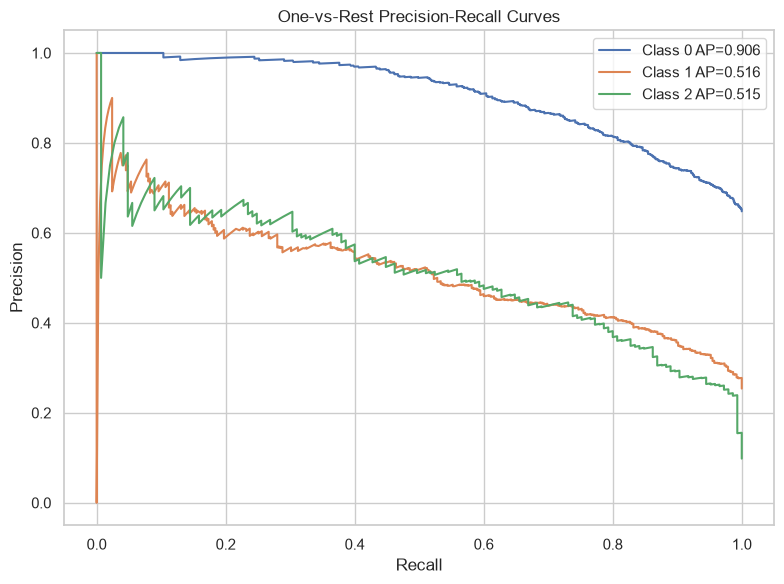

In [10]:
best_model=tuned if comparison.iloc[0]['model']=='Tuned Random Forest' else (hgb if comparison.iloc[0]['model']=='HistGradientBoosting' else baseline)
proba=best_model.predict_proba(X_test); classes=np.array(sorted(y.unique())); y_bin=label_binarize(y_test,classes=classes)
plt.figure(figsize=(8,6)); ap_rows=[]
for i,c in enumerate(classes):
    precision,recall,_=precision_recall_curve(y_bin[:,i],proba[:,i]); ap=average_precision_score(y_bin[:,i],proba[:,i]); ap_rows.append({'class':int(c),'average_precision':ap}); plt.plot(recall,precision,label=f'Class {c} AP={ap:.3f}')
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('One-vs-Rest Precision-Recall Curves'); plt.legend(); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'precision_recall_curves.png',dpi=300); plt.show()
pd.DataFrame(ap_rows).to_csv(OUTPUT_DIR/'average_precision_by_class.csv',index=False)


### Permutation Importance
Permutation importance measures the reduction in macro F1 when a feature is shuffled on the holdout data.

,feature,importance_mean,importance_std
0,location_code,0.1787,0.0119
6,total_log_volume,0.1238,0.0130
8,mean_log_volume,0.0791,0.0137
5,log_feature_count,0.0483,0.0079
2,severity_code_max,0.0402,0.0082
7,max_log_volume,0.0371,0.0110
3,event_type_count,0.0148,0.0047
4,resource_type_count,0.0067,0.0028
1,severity_type_count,0.0000,0.0000


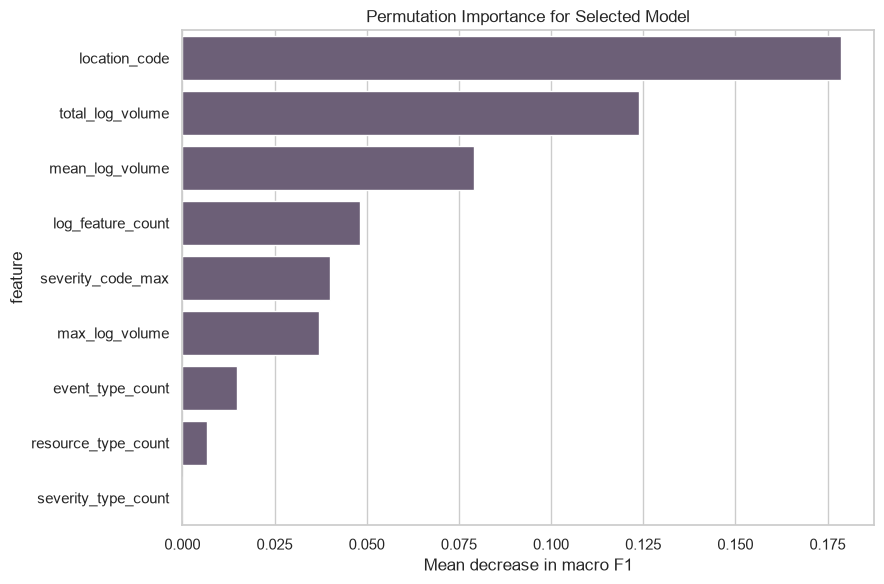

In [11]:
perm=permutation_importance(best_model,X_test,y_test,n_repeats=20,random_state=RANDOM_STATE,scoring='f1_macro',n_jobs=-1)
perm_df=pd.DataFrame({'feature':feature_cols,'importance_mean':perm.importances_mean,'importance_std':perm.importances_std}).sort_values('importance_mean',ascending=False)
display(perm_df.round(4)); perm_df.to_csv(OUTPUT_DIR/'permutation_importance.csv',index=False)
plt.figure(figsize=(9,6)); sns.barplot(data=perm_df,x='importance_mean',y='feature',color='#6C5B7B'); plt.title('Permutation Importance for Selected Model'); plt.xlabel('Mean decrease in macro F1'); plt.tight_layout(); plt.savefig(OUTPUT_DIR/'permutation_importance.png',dpi=300); plt.show()


### Export Final Evidence and Reproducibility Metadata

In [12]:
final_summary={'baseline_holdout_accuracy':float(accuracy_score(y_test,base_pred)),'baseline_holdout_macro_f1':float(f1_score(y_test,base_pred,average='macro')),'selected_model':str(comparison.iloc[0]['model']),'selected_holdout_macro_f1':float(comparison.iloc[0]['macro_f1']),'random_state':RANDOM_STATE,'records':{'cellular':len(cellular),'speed_tests':len(speed_tests),'telstra_faults':len(fault)}}
with open(OUTPUT_DIR/'milestone3_summary.json','w') as f: json.dump(final_summary,f,indent=2)
print(json.dumps(final_summary,indent=2)); print('Outputs saved to',OUTPUT_DIR.resolve())


{
  "baseline_holdout_accuracy": 0.6404874746106973,
  "baseline_holdout_macro_f1": 0.5871808961522995,
  "selected_model": "HistGradientBoosting",
  "selected_holdout_macro_f1": 0.6077887392839673,
  "random_state": 42,
  "records": {
    "cellular": 462,
    "speed_tests": 275078,
    "telstra_faults": 7381
  }
}
Outputs saved to /Users/athazh341@apac.comcast.com/Library/CloudStorage/OneDrive-Comcast/AkhilAnandTM/BVU/DSC680/Assignments/Week4/milestone3_outputs


### Interpretation and Deployment Guidance
Use the enhanced results to determine whether tuning improves macro F1 without creating an unacceptable false-positive burden. Before operational deployment, validate chronologically, define an operator-approved degradation label, test error rates across regions and technologies, monitor drift, protect production data, and keep engineers in the decision loop.